<a href="https://colab.research.google.com/github/Ayesh2002/ml-student-dropout/blob/RF/02_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 01. Set up the notebook

In [2]:
import hashlib
import io
import json
import os
import urllib.request
import uuid
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, f1_score, make_scorer, recall_score,
)
from sklearn.model_selection import (
    GridSearchCV, ParameterSampler, StratifiedKFold,
    cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
SEARCH_JOBS = min(2, os.cpu_count() or 1)
RUN_ID = uuid.uuid4().hex[:8]

RESULTS = Path("rf_results") / RUN_ID
RESULTS.mkdir(parents=True, exist_ok=True)

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


##2. Load and inspect the dataset

In [3]:
DATA_URL = (
    "https://raw.githubusercontent.com/Ayesh2002/ml-student-dropout/"
    "5d932c6ff712451a084f57a6dd2df39fb6277890/data/student_dropout_academic_.csv"
)

with urllib.request.urlopen(DATA_URL, timeout=60) as response:
    data_bytes = response.read()

df = pd.read_csv(io.BytesIO(data_bytes))
df.columns = df.columns.str.strip()

assert df.shape == (4424, 37)
assert set(df["Target"]) == {"Dropout", "Enrolled", "Graduate"}

print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate records:", int(df.duplicated().sum()))
print(df["Target"].value_counts())

display(df.head())

Dataset shape: (4424, 37)
Missing values: 0
Duplicate records: 0
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


##3. Select the 24 first-semester features

In [4]:
enrollment_features = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Previous qualification (grade)",
    "Nationality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Admission grade",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Age at enrollment",
    "International",
]

semester_features = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
]

features = enrollment_features + semester_features

assert len(features) == len(set(features)) == 24
assert set(features).issubset(df.columns)
assert "Target" not in features

X = df[features].copy()
y = df["Target"].copy()

print("Input shape:", X.shape)

Input shape: (4424, 24)


##4. Split the students and inspect training outcomes

Training students: 3539
Reserved benchmark students: 885


,Training students
Target,
Graduate,1767
Dropout,1137
Enrolled,635


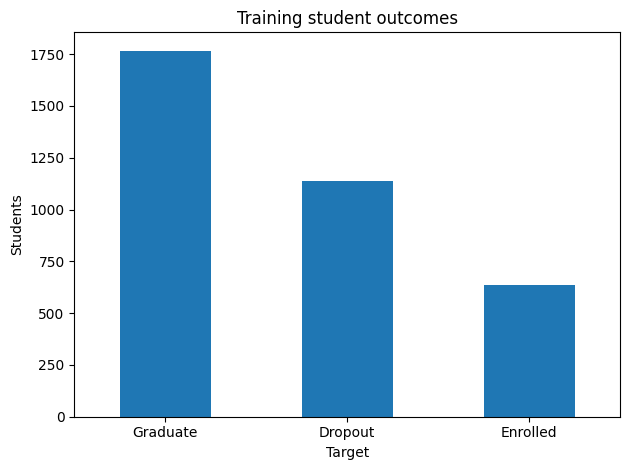

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

assert X_train.index.intersection(X_test.index).empty
assert len(X_train) == 3539
assert len(X_test) == 885

print("Training students:", len(X_train))
print("Reserved benchmark students:", len(X_test))

display(
    y_train.value_counts()
    .rename("Training students")
    .to_frame()
)

y_train.value_counts().plot.bar(
    title="Training student outcomes",
    rot=0,
)
plt.ylabel("Students")
plt.tight_layout()
plt.show()

##5. Build preprocessing and the RF baseline

In [6]:
categorical = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nationality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]

numeric = [
    column for column in features
    if column not in categorical
]

preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]),
        categorical,
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric,
    ),
])

baseline = Pipeline([
    ("prep", preprocessor),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=200,
            random_state=SEED,
            n_jobs=1,
        ),
    ),
])

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "dropout_recall": make_scorer(
        recall_score,
        labels=["Dropout"],
        average="macro",
        zero_division=0,
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

print("Pipeline ready. No model has been fitted yet.")

Pipeline ready. No model has been fitted yet.


##6. Measure baseline performance using training cross-validation

In [7]:
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=SEARCH_JOBS,
    error_score="raise",
)

baseline_summary = pd.Series(
    {
        "Training accuracy": baseline_cv["train_accuracy"].mean(),
        **{
            f"CV {metric}": baseline_cv[f"test_{metric}"].mean()
            for metric in scoring
        },
    },
    name="Original RF",
)

display(baseline_summary.round(4).to_frame())
baseline_summary.to_csv(RESULTS / "baseline_cv.csv")

,Original RF
Training accuracy,1.0000
CV accuracy,0.7160
CV macro_f1,0.5950
CV balanced_accuracy,0.5981
CV dropout_recall,0.6992
